# S4–S5 · Regression arms at a strictly matched budget

Weeks 4–5 compare six regression arms that share the backbone (2.5D U-Net), the data, the folds, the number of steps and
the seeds; only the objective changes.

| Arm | Objective | Role |
|---|---|---|
| R1 | L1 in HU | current practice (Bayes act: median) |
| R2 | L2 in HU | control (mean in HU) |
| R3 | L2 in SPR | Bayes act for squared range error (docs/theory.md, Proposition 4) |
| R4 | R3 + per-tissue SPR offset, cross-fitted | mandatory cheap control |
| R5 | R3 + λ · mean ΔWET² over plan beams and random directions | method |
| R6 | R5 + β · FZ0 score of a per-ray (VaR, ES) head | method, tails |

The question and the decision rule are fixed in `configs/s4_preregistration.json` before real predictions exist:
does R5 or R6 lower the CVaR90 of the range error to the distal target edge relative to R3 at an MAE within 5 %, and
does it beat the bias-corrected R4? If only R3 is beaten, the gain is a tissue-level bias and *the right estimator
suffices*, which is publishable on its own (plan, S6). The verdict uses the range proxy; the γ-proton part of go/no-go 2
needs the S6 dosimetry subset.

The notebook runs the code of this repository (`src/`), whether or not the package is installed. Environment variables:
`SYNTHRAD2025_ROOT`, `SCT_RUNS_ROOT` (default `outputs/s4/runs`, laid out as `seed<k>/<arm>`), `SCT_CACHE_DIR`,
`SCT_TASK`, `SCT_SEEDS` (default `0,1,2`), `SCT_TRAIN_IN_NOTEBOOK=1`. On real data, train with `sctrange-train --arm`
(README, weeks 4–5) and rerun this notebook. Without the dataset a synthetic fixture is used with one seed and tiny
models: **fixture numbers validate the pipeline only and carry no scientific meaning.**

### Setup · install `sctrange` from the repository

Run this cell first. Inside a clone of [hashirama21/sct-range](https://github.com/hashirama21/sct-range) it installs that
clone in editable mode (`pip install -e ".[dose]"`), so the notebook always runs the repository's code, local edits
included. Opened on its own (Colab, another machine), it first downloads the repository from GitHub (no git needed;
`SCTRANGE_REF` selects a branch, tag or commit, default `main`; `SCTRANGE_HOME` the destination), then installs it.
pip only runs when `sctrange` is missing or installed from elsewhere; `SCTRANGE_REINSTALL=1` forces it.

In [1]:
import importlib
import importlib.util
import io
import os
import shutil
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

REPO_URL = "https://github.com/hashirama21/sct-range"
REPO_REF = os.environ.get("SCTRANGE_REF", "main")


def find_repo(start: Path) -> Path | None:
    return next((p for p in (start, *start.parents) if (p / "pyproject.toml").exists() and (p / "src" / "sctrange").is_dir()),
                None)


def download_repo(destination: Path) -> Path:
    """Fetch ``REPO_REF`` of the GitHub repository as a zip archive and unpack it to ``destination``."""
    with urllib.request.urlopen(f"{REPO_URL}/archive/{REPO_REF}.zip", timeout=120) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    top = archive.namelist()[0].split("/")[0]
    staging = destination.with_name(destination.name + ".partial")
    shutil.rmtree(staging, ignore_errors=True)
    archive.extractall(staging)
    (staging / top).rename(destination)
    shutil.rmtree(staging, ignore_errors=True)
    return destination


REPO_ROOT = find_repo(Path.cwd())
if REPO_ROOT is None:
    REPO_ROOT = Path(os.environ.get("SCTRANGE_HOME", Path.cwd() / "sct-range")).resolve()
    if find_repo(REPO_ROOT) is None:
        print(f"downloading {REPO_URL} @ {REPO_REF} to {REPO_ROOT}")
        download_repo(REPO_ROOT)
    os.chdir(REPO_ROOT / "notebooks")
SOURCE_DIR = (REPO_ROOT / "src").resolve()


def installed_from_repo() -> bool:
    spec = importlib.util.find_spec("sctrange")
    return spec is not None and spec.origin is not None and Path(spec.origin).resolve().is_relative_to(SOURCE_DIR)


if os.environ.get("SCTRANGE_REINSTALL") == "1" or not installed_from_repo():
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--editable", f"{REPO_ROOT}[dose]"], check=True)
# an editable install is only picked up by new processes; make it visible to this kernel too
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))
for module in [name for name in sys.modules if name == "sctrange" or name.startswith("sctrange.")]:
    del sys.modules[module]
importlib.invalidate_caches()

import sctrange

assert Path(sctrange.__file__).resolve().is_relative_to(SOURCE_DIR), f"sctrange imported from {sctrange.__file__}"
print(f"sctrange {sctrange.__version__} installed from {REPO_ROOT.name}/src (editable)")

sctrange 0.4.0 installed from sct-range/src (editable)


In [2]:
import json
import os
import warnings
from dataclasses import asdict

warnings.filterwarnings("ignore", message=r"`torch\.jit\.script` is deprecated")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from sctrange.cache import VolumeCache
from sctrange.correction import crossfit_bias_correction
from sctrange.data import discover_cases, load_case, read_volume
from sctrange.diagnostics import Preregistration, decide_arms, holm, paired_test
from sctrange.evaluation import DiagnosticConfig, evaluate_case, evaluate_risk
from sctrange.hlut import HLUT
from sctrange.phantoms import write_fixture_dataset
from sctrange.plotting import apply_style, plot_arm_pareto, plot_training_curves
from sctrange.split import SplitSpec, load_split, split_hash, stratified_split, write_split
from sctrange.training import ARMS, arm_config, crossfit

In [3]:
DATA_ROOT = Path(os.environ.get("SYNTHRAD2025_ROOT", REPO_ROOT / "data" / "synthrad2025"))
OUTPUT_DIR = REPO_ROOT / "outputs" / "s4"
FIGURE_DIR = OUTPUT_DIR / "figures"
RUNS_ROOT = Path(os.environ.get("SCT_RUNS_ROOT", OUTPUT_DIR / "runs"))
CACHE_DIR = Path(os.environ.get("SCT_CACHE_DIR", OUTPUT_DIR / "cache"))
FROZEN_SPLIT_PATH = REPO_ROOT / "splits" / "synthrad2025_local_test.json"
PREREGISTRATION_PATH = REPO_ROOT / "configs" / "s4_preregistration.json"
TASK = os.environ.get("SCT_TASK", "1")

SEED = 20261013
SEEDS = tuple(int(s) for s in os.environ.get("SCT_SEEDS", "0,1,2").split(","))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TRAINED_ARMS = tuple(sorted(ARMS))
ARM_ORDER = ("R1", "R2", "R3", "R4", "R5", "R6")
N_FOLDS = 5
DIAGNOSTIC = DiagnosticConfig(angles_deg=tuple(range(0, 360, 45)), target_radius_mm=25.0, seed=SEED, device=DEVICE)
MAX_CASES = None
OVERRIDES: dict = {}
hlut = HLUT.pyradplan_default()

USE_FIXTURE = not DATA_ROOT.exists() or next(DATA_ROOT.rglob("ct.mha"), None) is None
if USE_FIXTURE:
    DATA_ROOT = OUTPUT_DIR / "fixture" / "data"
    if next(DATA_ROOT.rglob("ct.mha"), None) is None:
        write_fixture_dataset(DATA_ROOT, centers=("A", "B", "C"), cases_per_stratum=5, seed=SEED)
    N_FOLDS, SEEDS = 2, (0,)
    OVERRIDES = dict(context=1, patch=96, batch_size=8, steps=150, warmup_steps=15, base_channels=16, depth=3,
                     log_every=25, samples_per_case=2000)
TRAIN_IN_NOTEBOOK = USE_FIXTURE or os.environ.get("SCT_TRAIN_IN_NOTEBOOK") == "1"
SPLIT_PATH = OUTPUT_DIR / "fixture_split.json" if USE_FIXTURE else FROZEN_SPLIT_PATH

torch.manual_seed(SEED)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
apply_style()
pd.set_option("display.width", 160)
print(f"task {TASK} · device {DEVICE} · folds {N_FOLDS} · seeds {SEEDS} · train in notebook: {TRAIN_IN_NOTEBOOK}"
      f"{' · synthetic fixture' if USE_FIXTURE else ''}")

task 1 · device cpu · folds 2 · seeds (0,) · train in notebook: True · synthetic fixture


## 1 · Frozen split and pre-registration

The frozen split of week 1 is verified, never regenerated on real data; test cases are never loaded. The
pre-registration file is hashed into the report.

In [4]:
records = discover_cases(DATA_ROOT)
if SPLIT_PATH.exists():
    split = load_split(SPLIT_PATH)
elif USE_FIXTURE:
    write_split(stratified_split(records, SplitSpec(seed=SEED)), SPLIT_PATH)
    split = load_split(SPLIT_PATH)
else:
    raise FileNotFoundError(f"{SPLIT_PATH} is missing: freeze the split first (week 1)")

development_ids = set(split["development"])
development = [r for r in records if r.case_id in development_ids and r.task == TASK][:MAX_CASES]
assert not development_ids & set(split["test"])

prereg = Preregistration.load(PREREGISTRATION_PATH)
display(pd.Series({"split sha256": split_hash(split), "development cases (this task)": len(development),
                   "test cases (never loaded)": len(split["test"]),
                   "pre-registration sha256": prereg.fingerprint}, name="value").to_frame())
display(pd.json_normalize({k: v for k, v in prereg.raw.items() if k != "verdicts"}, sep=" · ").T.rename(columns={0: "value"}))

,value
split sha256,1d1a8dd4bb68b3d1e366125a2afbff70aa43e5a462e5f1...
development cases (this task),36
test cases (never loaded),9
pre-registration sha256,996db53bf057f9224d084fda0aa512e370c4cefbc95ba5...


,value
version,1
registered,2026-10-22
question,"At a strictly matched budget, does a range-awa..."
primary_metric,target_cvar_mm
reference_arm,R3
control_arm,R4
method_arms,"[R5, R6]"
mae_relative_tolerance,0.05
alpha,0.05
aggregation,per-case metrics averaged over seeds before te...


## 2 · Training (cross-fitted) and the R4 control

For every seed, each trained arm is cross-fitted on the development pool; R4 is then derived from the out-of-fold R3
predictions, with offsets for fold *k* estimated on the other folds only. Checkpoints are reused when they match the
configuration and refused otherwise, so reruns are cheap and arms cannot be mixed up.

36 new cases cached


missing runs: none


,R6 configuration
loss,l2_spr
context,1
patch,96
batch_size,8
steps,150
learning_rate,0.0002
weight_decay,0.0001
warmup_steps,15
base_channels,16
depth,3


R4 SPR offset by predicted class  [-inf, -500) HU  [-500, -100) HU  [-100, 150) HU  [150, inf) HU
seed fold                                                                                        
0    0                                     0.0656           0.0652          0.0070        -0.0092
     1                                     0.0795           0.0895         -0.0115        -0.0163

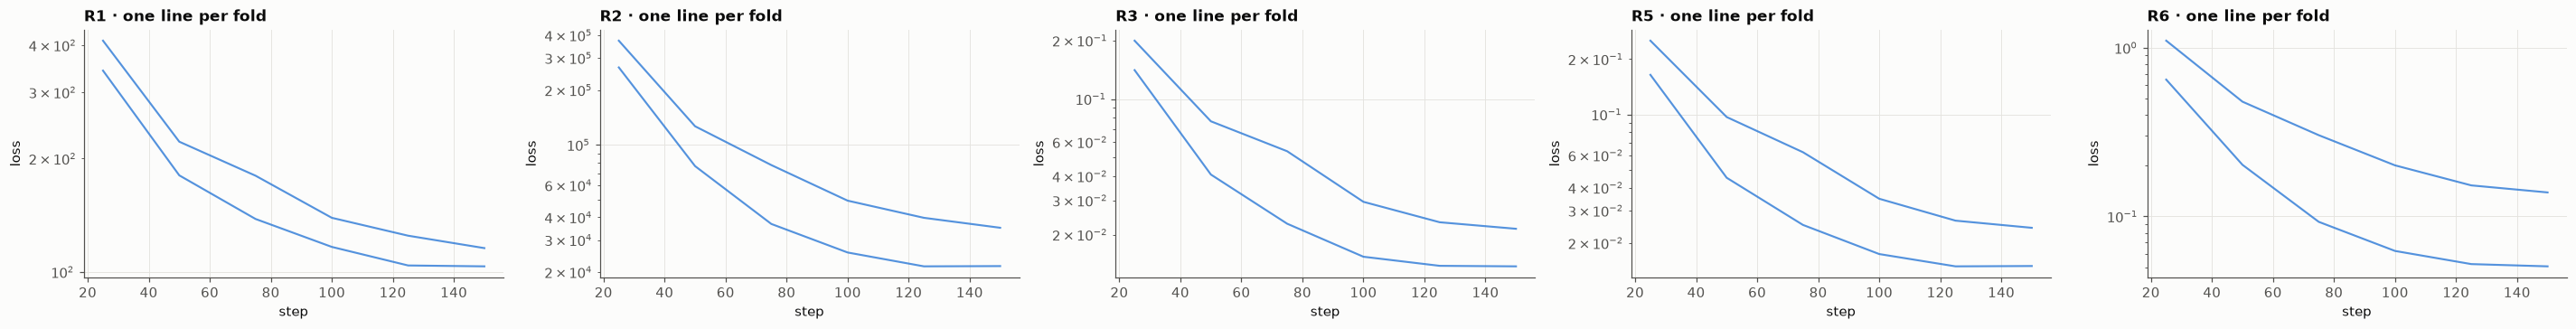

In [5]:
cache = VolumeCache(CACHE_DIR)
print(f"{cache.build(development)} new cases cached")

histories, missing, offsets = {}, [], {}
for seed in SEEDS:
    seed_dir = RUNS_ROOT / f"seed{seed}"
    for arm in TRAINED_ARMS:
        run_dir = seed_dir / arm
        if TRAIN_IN_NOTEBOOK:
            crossfit(development, cache, arm_config(arm, seed=seed, device=DEVICE, **OVERRIDES), hlut, N_FOLDS, run_dir)
        if not (run_dir / "predictions").exists():
            missing.append(f"seed{seed}/{arm}")
        elif (run_dir / "history.csv").exists() and seed == SEEDS[0]:
            histories[arm] = pd.read_csv(run_dir / "history.csv")
    if (seed_dir / "R3" / "folds.csv").exists():
        offsets[seed] = crossfit_bias_correction(development, seed_dir / "R3", seed_dir / "R4", hlut)
    else:
        missing.append(f"seed{seed}/R4 (needs R3)")

print("missing runs:", ", ".join(missing) if missing else "none")
display(pd.Series(asdict(arm_config("R6", seed=SEEDS[0], device=DEVICE, **OVERRIDES)), name="R6 configuration").to_frame())
if offsets:
    display(pd.concat(offsets, names=["seed"]).round(4).rename_axis(columns="R4 SPR offset by predicted class"))
if histories:
    plot_training_curves(histories).savefig(FIGURE_DIR / "training_curves.png", bbox_inches="tight")
    plt.show()

## 3 · Per-case evaluation

Every out-of-fold prediction of every arm and seed is evaluated with the S1 metrics (8 coplanar beams, 25 mm surrogate
target at the body centroid). R6 risk maps are integrated along the same segments to check the calibration of the
predicted VaR90 and ES90. Per-case metrics are averaged over seeds before any test.

In [6]:
rows, risk_rows = [], []
for record in development:
    volumes = load_case(record, ("ct", "mask"))
    ct, mask, spacing = volumes["ct"].array, volumes["mask"].array, volumes["ct"].spacing
    for seed in SEEDS:
        for arm in ARM_ORDER:
            run_dir = RUNS_ROOT / f"seed{seed}" / arm
            path = run_dir / "predictions" / f"{record.case_id}.mha"
            if not path.exists():
                continue
            sct = read_volume(path).array
            keys = {"case_id": record.case_id, "region": record.region, "center": record.center, "seed": seed, "source": arm}
            rows.append({**keys, **evaluate_case(ct, mask, sct, spacing, hlut, DIAGNOSTIC)})
            var_path = run_dir / "risk" / f"{record.case_id}_var.mha"
            if var_path.exists():
                var = read_volume(var_path).array
                excess = read_volume(run_dir / "risk" / f"{record.case_id}_excess.mha").array
                risk_rows.append({**keys, **evaluate_risk(ct, mask, sct, var, excess, spacing, hlut, DIAGNOSTIC)})

per_seed = pd.DataFrame(rows)
per_seed.to_csv(OUTPUT_DIR / "s4_per_seed.csv", index=False)
numeric = [c for c in per_seed.columns if c not in ("case_id", "region", "center", "seed", "source")]
diagnostics = per_seed.groupby(["case_id", "region", "center", "source"], as_index=False)[numeric].mean()
diagnostics.to_csv(OUTPUT_DIR / "s4_diagnostics.csv", index=False)
risk = pd.DataFrame(risk_rows)
print(f"{diagnostics['case_id'].nunique()} cases · arms {sorted(diagnostics['source'].unique())} · "
      f"{len(per_seed)} evaluations over {len(SEEDS)} seed(s)")

columns = ["mae_hu", "target_mean_signed_mm", "target_rms_mm", "target_p95_mm", "target_cvar_mm", "target_coherence",
           "target_global_ratio"]
order = [arm for arm in ARM_ORDER if arm in set(diagnostics["source"])]
display(diagnostics.groupby("source")[columns].median().reindex(order).round(3))

36 cases · arms ['R1', 'R2', 'R3', 'R4', 'R5', 'R6'] · 216 evaluations over 1 seed(s)


,mae_hu,target_mean_signed_mm,target_rms_mm,target_p95_mm,target_cvar_mm,target_coherence,target_global_ratio
source,,,,,,,
R1,97.141,-0.966,3.663,8.013,8.430,0.484,1.675
R2,100.033,-1.430,4.493,7.782,8.051,0.542,1.192
R3,122.921,-2.518,3.537,6.434,6.591,0.518,1.144
R4,100.511,-1.516,3.206,6.454,6.735,0.387,1.184
R5,122.754,-1.395,3.546,6.656,7.015,0.352,1.179
R6,134.523,-2.371,4.124,7.325,7.788,0.455,1.161


## 4 · Image error versus range-error tail

Figure 4 of the plan: one point per arm at the median over cases, whiskers spanning the interquartile range. Lower left
is better. The theory predicts that R3 improves on R1 mostly on the signed bias and the tail, not on MAE, and that any
gain of R5 or R6 shows on the vertical axis.

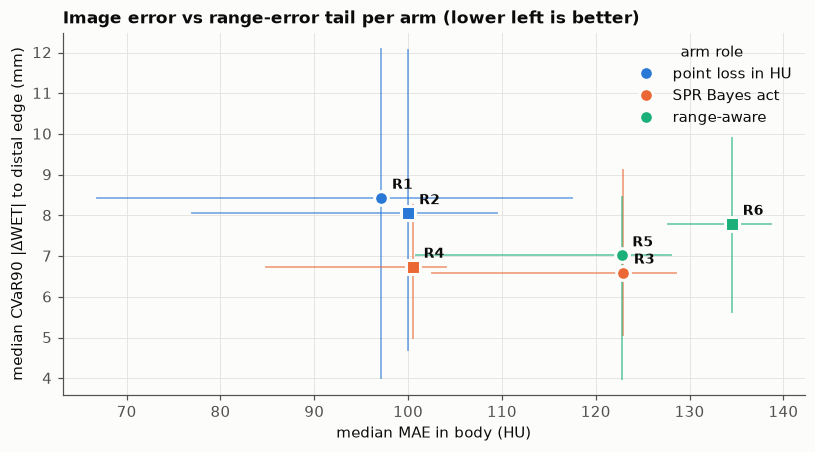

,mae_hu,mae_hu_q25,mae_hu_q75,target_cvar_mm,target_cvar_mm_q25,target_cvar_mm_q75
source,,,,,,
R1,97.141,66.792,117.499,8.430,3.998,12.086
R2,100.033,76.981,109.483,8.051,4.692,12.061
R3,122.921,102.598,128.543,6.591,5.066,9.116
R4,100.511,84.807,104.016,6.735,4.988,8.261
R5,122.754,100.854,127.974,7.015,3.990,8.443
R6,134.523,127.675,138.670,7.788,5.633,9.901


median signed ΔWET (mm),R1,R2,R3,R4,R5,R6
region,,,,,,
AB,0.456,-0.960,-0.712,-0.014,-0.328,-1.118
HN,-1.956,-2.032,-2.461,-2.144,-1.253,-2.371
TH,0.874,-2.355,-4.307,-0.064,-3.920,-2.473


In [7]:
grouped = diagnostics.groupby("source")
pareto = pd.concat({f"{metric}{suffix}": grouped[metric].quantile(q)
                    for metric in ("mae_hu", "target_cvar_mm")
                    for suffix, q in (("", 0.5), ("_q25", 0.25), ("_q75", 0.75))}, axis=1).reindex(order)
plot_arm_pareto(pareto).savefig(FIGURE_DIR / "fig4_pareto.png", bbox_inches="tight")
plt.show()
display(pareto.round(3))
display(diagnostics.pivot_table(index="region", columns="source", values="target_mean_signed_mm", aggfunc="median")
        .reindex(columns=order).round(3).rename_axis(columns="median signed ΔWET (mm)"))

## 5 · Pre-registered decision and secondary tests

The verdict applies `configs/s4_preregistration.json` unchanged. Secondary tests are reported whatever the verdict:
Proposition 5 on patients (signed abdominal range bias of R1 above R3, one-sided), and the MAE cost of each arm relative
to R3 (two-sided), all Holm-adjusted within this family.

In [8]:
decision = decide_arms(diagnostics, prereg)
display(pd.Series({k: v for k, v in decision.items() if k not in ("arms", "raw_p_values")}, name="value").to_frame())
display(pd.DataFrame(decision["arms"]).T.round(4))

secondary = {"signed bias AB, R1 − R3 > 0": paired_test(diagnostics, "target_mean_signed_mm", "R1", "R3", "AB", "greater")}
for arm in ("R1", "R2", "R4", "R5", "R6"):
    secondary[f"MAE {arm} − R3"] = paired_test(diagnostics, "mae_hu", arm, "R3")
adjusted = holm({name: result["p_value"] for name, result in secondary.items()})
secondary_table = pd.DataFrame(secondary).T.assign(p_holm=pd.Series(adjusted))
display(secondary_table.round(4))
if USE_FIXTURE:
    print("Fixture run: the verdict exercises the decision code only.")

,value
verdict,BIAS CORRECTION SUFFICES
metric,target_cvar_mm
preregistration_sha256,996db53bf057f9224d084fda0aa512e370c4cefbc95ba5...


,p_vs_reference_holm,p_vs_control_holm,median_relative_mae_change,mae_within_tolerance
R5,0.000009,0.417832,0.002781,True
R6,1.0,1.0,0.051846,False


,cases,median_difference,p_value,p_holm
"signed bias AB, R1 − R3 > 0",12.0,0.7713,0.0647,0.1294
MAE R1 − R3,36.0,-30.1835,0.0000,0.0000
MAE R2 − R3,36.0,-18.3553,0.0000,0.0000
MAE R4 − R3,36.0,-19.4600,0.0000,0.0000
MAE R5 − R3,36.0,0.3581,0.6247,0.6247
MAE R6 − R3,36.0,6.3206,0.0001,0.0004


Fixture run: the verdict exercises the decision code only.


## 6 · Calibration of the R6 risk head

A calibrated head covers 90 % of rays with its VaR90 (`risk_coverage` ≈ 0.9), and the mean |ΔWET| beyond the predicted
VaR matches the predicted ES (`risk_realised_es_mm` ≈ `risk_mean_es_mm`). `risk_spearman` is the rank correlation
between predicted VaR and realised |ΔWET| over rays: the head is only useful for failure detection if it is positive.

In [9]:
risk_columns = ["risk_rays", "risk_coverage", "risk_mean_var_mm", "risk_mean_es_mm", "risk_realised_es_mm", "risk_fz",
                "risk_spearman"]
if risk.empty:
    print("no risk maps found (R6 not trained yet)")
else:
    risk.to_csv(OUTPUT_DIR / "s4_risk.csv", index=False)
    calibration = risk.groupby("region")[risk_columns].median()
    calibration.loc["all"] = risk[risk_columns].median()
    display(calibration.round(3))

,risk_rays,risk_coverage,risk_mean_var_mm,risk_mean_es_mm,risk_realised_es_mm,risk_fz,risk_spearman
region,,,,,,,
AB,2328.0,0.559,4.721,4.436,6.856,6.628,-0.143
HN,2332.0,0.608,2.613,3.397,3.563,2.967,0.259
TH,2336.0,0.433,4.482,5.003,5.545,4.468,0.123
all,2332.0,0.475,3.135,3.842,4.805,3.957,0.135


## 7 · Report

In [10]:
report = {
    "fixture": USE_FIXTURE,
    "task": TASK,
    "seeds": list(SEEDS),
    "folds": N_FOLDS,
    "split_sha256": split_hash(split),
    "overrides": OVERRIDES,
    "decision": decision,
    "secondary": secondary_table.to_dict(orient="index"),
    "medians_by_arm": diagnostics.groupby("source")[columns].median().to_dict(orient="index"),
    "risk_calibration": {} if risk.empty else risk[risk_columns].median().to_dict(),
    "missing_runs": missing,
}
(OUTPUT_DIR / "s4_report.json").write_text(json.dumps(report, indent=2, default=float))
status = pd.DataFrame([
    ("Frozen split verified", split_hash(split)[:12], True),
    ("Pre-registration hashed", prereg.fingerprint[:12], True),
    ("All arms and seeds present", ", ".join(missing) or "complete", not missing),
    ("R6 risk maps evaluated", f"{len(risk)} evaluations", not risk.empty),
    ("Verdict on real data", decision["verdict"], not USE_FIXTURE and decision["verdict"] != "NOT EVALUATED"),
], columns=["item", "detail", "passed"])
display(status)

,item,detail,passed
0,Frozen split verified,1d1a8dd4bb68,True
1,Pre-registration hashed,996db53bf057,True
2,All arms and seeds present,complete,True
3,R6 risk maps evaluated,36 evaluations,True
4,Verdict on real data,BIAS CORRECTION SUFFICES,False


## What each verdict implies for S6 onwards

| Verdict | Next |
|---|---|
| GAIN | Dosimetry on the 20-case subset (S6) for R1, R3, R4, R5, R6; the γ-proton test completes go/no-go 2. |
| BIAS CORRECTION SUFFICES | The paper becomes "the right estimator suffices": theory (Results A–C), R1 vs R3 vs R4, tails via R6 and the generative arm. |
| NO GAIN | Range loss dropped as a contribution; the paper rests on estimator choice, tails and projected CRPS (Results B–C). |

Whatever the verdict, the generative arm (S7–S8) is compared with R6 on tails and with R3 on the mean, where the theory
predicts equality at best.